In [1]:
# Load Data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

df = pd.read_csv("../data/HR_Analytics.csv")
print(df.shape)
print(df.columns.tolist())

(1480, 38)
['EmpID', 'Age', 'AgeGroup', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'SalarySlab', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [2]:
df = df.drop_duplicates(subset="EmpID")
df["AttritionFlag"] = (df["Attrition"] == "Yes").astype(int)

print(df.shape)                       # expect (1470, ...)
print(df["AttritionFlag"].sum())      # expect 237
print(df["AttritionFlag"].mean().round(3))  # expect 0.161

(1470, 39)
237
0.161


In [3]:
#Select the factors to test

drop_cols = ["EmpID", "EmployeeNumber", "Attrition", "AttritionFlag",
             "AgeGroup", "SalarySlab",
             "EmployeeCount", "StandardHours", "Over18"]

features = df.drop(columns=[c for c in drop_cols if c in df.columns])
features = features.loc[:, features.nunique() > 1]   # drop constant columns

num_cols = features.select_dtypes(include="number").columns
cat_cols = features.select_dtypes(exclude="number").columns
print("Numeric:", list(num_cols))
print("Categorical:", list(cat_cols))

Numeric: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Categorical: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [4]:
#Numeric factors (correlation with attrition)

num_res = pd.DataFrame({
    "Factor": num_cols,
    "Strength": [df[c].corr(df["AttritionFlag"]) for c in num_cols],
})
num_res["Type"] = "Numeric"
num_res["Direction"] = np.where(num_res["Strength"] > 0,
                                "Higher value = more attrition",
                                "Higher value = less attrition")
num_res.sort_values("Strength", key=abs, ascending=False).head(10)

,Factor,Strength,Type,Direction
16,TotalWorkingYears,-0.171063,Numeric,Higher value = less attrition
7,JobLevel,-0.169105,Numeric,Higher value = less attrition
22,YearsWithCurrManager,-0.162117,Numeric,Higher value = less attrition
20,YearsInCurrentRole,-0.160545,Numeric,Higher value = less attrition
9,MonthlyIncome,-0.159840,Numeric,Higher value = less attrition
0,Age,-0.159205,Numeric,Higher value = less attrition
15,StockOptionLevel,-0.137145,Numeric,Higher value = less attrition
19,YearsAtCompany,-0.134392,Numeric,Higher value = less attrition
6,JobInvolvement,-0.130016,Numeric,Higher value = less attrition
8,JobSatisfaction,-0.103481,Numeric,Higher value = less attrition


- Every top factor is negative: higher values mean less attrition.
- All are weak, between -0.10 and -0.17. No numeric factor strongly predicts attrition on its own.
- Seven of the top ten (`TotalWorkingYears`, `JobLevel`, `YearsWithCurrManager`, `YearsInCurrentRole`, `MonthlyIncome`, `Age`, `YearsAtCompany`) describe the same thing: seniority and career stage. Older, more experienced, higher-level and better-paid employees tend to stay. Because they’re likely closely related to each other, count them as one theme, not seven independent causes.
- `StockOptionLevel` (-0.137) suggests employees with stock options are less likely to leave.
- `JobInvolvement` and JobSatisfaction show the expected direction, but weakly.
Everything outside the top ten is below 0.10, so effectively unrelated.

In [5]:
# Categorical factors(Cramér’s V)

def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    r, k = table.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

cat_res = pd.DataFrame({
    "Factor": cat_cols,
    "Strength": [cramers_v(df[c], df["AttritionFlag"]) for c in cat_cols],
})
cat_res["Type"] = "Categorical"
cat_res["Direction"] = "n/a (categorical)"
cat_res.sort_values("Strength", ascending=False)

,Factor,Strength,Type,Direction
6,OverTime,0.244065,Categorical,n/a (categorical)
4,JobRole,0.242142,Categorical,n/a (categorical)
5,MaritalStatus,0.177211,Categorical,n/a (categorical)
0,BusinessTravel,0.131315,Categorical,n/a (categorical)
2,EducationField,0.104409,Categorical,n/a (categorical)
1,Department,0.085698,Categorical,n/a (categorical)
3,Gender,0.027565,Categorical,n/a (categorical)


- OverTime (0.244) is the strongest factor overall, between small and medium.
- JobRole (0.242) is almost tied with OverTime. Compare it with `Department` (0.086): roles differ far more than departments, so the department view hides which specific roles are at risk.
- MaritalStatus (0.177) is moderate. Check Page 2 to see which group drives it.
- BusinessTravel (0.131) and EducationField (0.104) are small effects.
- Department (0.086) is weak. Gender (0.028) is negligible, so there’s no meaningful attrition difference by gender.

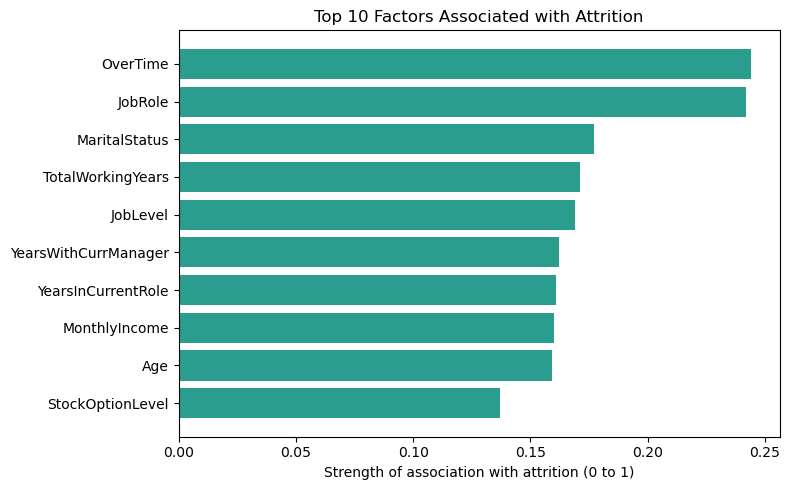

,Factor,Strength,Type,Direction,AbsStrength,Rank
0,OverTime,0.244,Categorical,n/a (categorical),0.244,1
1,JobRole,0.242,Categorical,n/a (categorical),0.242,2
2,MaritalStatus,0.177,Categorical,n/a (categorical),0.177,3
3,TotalWorkingYears,-0.171,Numeric,Higher value = less attrition,0.171,4
4,JobLevel,-0.169,Numeric,Higher value = less attrition,0.169,5
5,YearsWithCurrManager,-0.162,Numeric,Higher value = less attrition,0.162,6
6,YearsInCurrentRole,-0.161,Numeric,Higher value = less attrition,0.161,7
7,MonthlyIncome,-0.160,Numeric,Higher value = less attrition,0.160,8
8,Age,-0.159,Numeric,Higher value = less attrition,0.159,9
9,StockOptionLevel,-0.137,Numeric,Higher value = less attrition,0.137,10


In [6]:
# Combine, rank, and plot

results = pd.concat([num_res, cat_res], ignore_index=True)
results["AbsStrength"] = results["Strength"].abs().round(3)
results = results.sort_values("AbsStrength", ascending=False).reset_index(drop=True)
results["Rank"] = results.index + 1
results["Strength"] = results["Strength"].round(3)

top10 = results.head(10).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top10["Factor"], top10["AbsStrength"], color="#2a9d8f")
plt.xlabel("Strength of association with attrition (0 to 1)")
plt.title("Top 10 Factors Associated with Attrition")
plt.tight_layout()
plt.savefig("../outputs/top_drivers.png", dpi=150, bbox_inches="tight")
plt.show()

results.head(10)

`OverTime` and `JobRole` lead clearly. The remaining factors are bunched between 0.14 and 0.18, so their exact order isn’t meaningful. Treat them as a group.

In [7]:
# Confirm with a Random Forest (quick sanity check)

from sklearn.ensemble import RandomForestClassifier

X = pd.get_dummies(features, drop_first=True)
rf = RandomForestClassifier(n_estimators=300, random_state=42,
                            class_weight="balanced")
rf.fit(X, df["AttritionFlag"])

importance = pd.Series(rf.feature_importances_, index=X.columns)
importance.sort_values(ascending=False).head(10)

MonthlyIncome           0.071318
Age                     0.060765
OverTime_Yes            0.057434
TotalWorkingYears       0.050149
DailyRate               0.049513
MonthlyRate             0.048432
HourlyRate              0.044173
YearsAtCompany          0.043431
DistanceFromHome        0.041370
YearsWithCurrManager    0.040212
dtype: float64

- Agreement: `OverTime`, `MonthlyIncome`, `Age`, `TotalWorkingYears` and `YearsWithCurrManager` appear in both rankings. These are your most reliable findings.
- `DailyRate`, `MonthlyRate`, `HourlyRate`, `DistanceFromHome` appear only here. Their correlations with attrition are below 0.10. Random Forest importance is known to favor numeric columns with many distinct values, and these pay-rate columns look like noise in this synthetic dataset. Don’t treat them as drivers.
- `JobRole` is missing because `get_dummies` split it into many columns, each getting a small share of its importance. This doesn’t mean it’s unimportant.
- The importances sum to 1, so the values (0.04 to 0.07) aren’t comparable to the correlation scale. Only the order matters.

## Conclusion

**Overall attrition:** 237 of 1,470 employees left (16.1%).

**Key findings**
1. **OverTime is the strongest factor associated with attrition** (Cramér's V = 0.24). Employees working overtime left at about 31%, versus 10% for those who did not.
2. **JobRole is almost as strong** (V = 0.24) and much stronger than Department (V = 0.09). Attrition differs more between specific roles than between departments, so role-level analysis is more useful than department-level.
3. **Seniority and career stage are consistently associated with lower attrition.** TotalWorkingYears, JobLevel, YearsWithCurrManager, YearsInCurrentRole, MonthlyIncome and Age all show weak negative correlations (-0.16 to -0.17). Younger, more junior, lower-paid employees leave more often. These variables overlap heavily, so they represent one theme rather than six separate effects.
4. **MaritalStatus** (V = 0.18) and **StockOptionLevel** (r = -0.14) are secondary factors.
5. **Gender (V = 0.03) is not meaningfully related to attrition.**

**Cross-check:** A Random Forest confirmed OverTime, MonthlyIncome, Age, TotalWorkingYears and YearsWithCurrManager as important. It also ranked DailyRate, MonthlyRate and HourlyRate highly, but these have near-zero correlation with attrition and are likely a known bias toward high-cardinality numeric columns, so they are not treated as drivers.

**Limitations**
- All effects are weak to moderate (the strongest is 0.24). No single factor explains attrition on its own.
- These are associations, not causes.
- Cramér's V and Pearson correlation are not strictly comparable, so the ranking is a guide.
- The dataset is synthetic, so findings illustrate the method rather than describe a real company.

**Implications for the dashboard (Page 3):** highlight overtime, job role, marital status and income/tenure comparisons between leavers and stayers.

In [8]:
results[["Rank", "Factor", "Type", "Strength", "AbsStrength", "Direction"]] \
    .to_csv("../outputs/correlation_results.csv", index=False)